# Tarea 1 – Analítica de Datos (MACI 2026)

**Alumno:** Keyden Urbina

**Mercado de celulares en Chile (solotodo.cl) y modelo de rango de precios**

Las cifras de las interpretaciones corresponden a la extracción del **07-11-2026 12:14** (web scraping del HTML, columna `fecha_extraccion`). Si vuelves a ejecutar el scraping, revisa los números antes de entregar.

## Objetivo 2 · Modelo de clasificación de rango de precio

### 2.1 Variable objetivo `rango_precio`

**Decisión clave:** se trabaja con **una fila por modelo nuevo** (precio = mediana de sus tiendas). Si se usara una fila por tienda, el mismo celular (mismas características) podría quedar en train y en test, y el modelo "se sabría la respuesta".

**Variables:** solo las características técnicas limpias. La **marca se excluye a propósito**: los equipos de la emprendedora no tienen historia de marca, así que el modelo debe estimar el precio por lo que el teléfono *trae*, no por el logo.

In [1]:
# Librerías que usa este notebook
import numpy as np                     # np.inf para el último tramo de precio
import pandas as pd                    # tablas
import matplotlib.pyplot as plt        # matriz de confusión e importancia de variables
from pathlib import Path               # rutas de carpetas

# Ruta a data/processed: la busca subiendo desde donde se ejecuta (sirve desde notebooks/ o desde la raíz)
PROC = next(p / "data" / "processed" for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "data" / "processed").is_dir())
print("Datos desde:", PROC / "data_processed.csv")

Datos desde: /Users/keydenurbina/Desktop/github/Proyecto Web Scraping/data/processed/data_processed.csv


In [2]:
from sklearn.model_selection import train_test_split, ParameterGrid
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, classification_report, ConfusionMatrixDisplay
from sklearn.inspection import permutation_importance

d = pd.read_csv(PROC / "data_processed.csv")
X_cols = ["memoria_gb", "ram_gb", "pantalla_pulg", "camara_principal_mp", "camara_frontal_mp", "bateria_mah", "peso_g", "nfc"]

# 1 fila por modelo nuevo (precio = mediana entre tiendas). Si no, el mismo celular caería en train y test → trampa.
m = d[d.reacondicionado == 0].groupby("nombre").agg({**{c: "first" for c in X_cols}, "precio_oferta": "median"})
etiquetas = ["Muy bajo", "Bajo", "Medio", "Alto", "Muy alto"]
m["rango_precio"] = pd.cut(m.precio_oferta, [0, 100_000, 200_000, 320_000, 570_000, np.inf], labels=False, right=False)  # [a, b)
m.rango_precio.value_counts().sort_index().rename(index=dict(enumerate(etiquetas)))

rango_precio
Muy bajo     7
Bajo        41
Medio       48
Alto        41
Muy alto    56
Name: count, dtype: int64

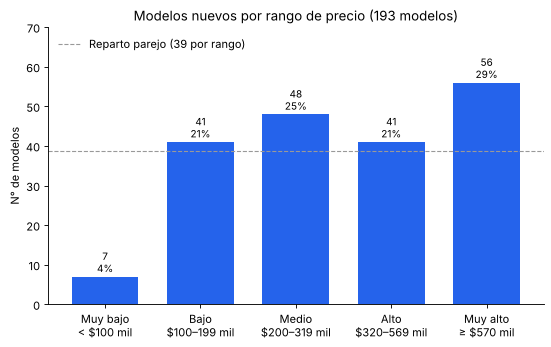

rango_precio
Muy bajo     7
Bajo        41
Medio       48
Alto        41
Muy alto    56
Name: count, dtype: int64

In [3]:
# Gráfico: cuántos modelos caen en cada rango de precio
conteo = m.rango_precio.value_counts().reindex(range(5), fill_value=0)     # n° de modelos por rango (0 a 4); si un rango queda vacío, pone 0
rangos = ["< $100 mil", "$100–199 mil", "$200–319 mil", "$320–569 mil", "≥ $570 mil"]
ax = conteo.plot.bar(figsize=(8, 4.5), color="#2563eb", width=0.7, rot=0)
ax.set_xticks(range(5), [f"{e}\n{r}" for e, r in zip(etiquetas, rangos)])  # etiqueta + rango de precio bajo cada barra
ax.bar_label(ax.containers[0], labels=[f"{v}\n{v/len(m):.0%}" for v in conteo], padding=2, fontsize=9)   # n° y % sobre cada barra
ax.axhline(len(m) / 5, color="#999", linestyle="--", linewidth=1,          # línea de referencia: si los 5 rangos fueran iguales
           label=f"Reparto parejo ({len(m) / 5:.0f} por rango)")
ax.legend(handles=ax.lines, loc="upper left", frameon=False)               # la leyenda solo explica la línea
ax.set_ylim(top=conteo.max() * 1.25)                                       # espacio para las etiquetas
ax.set(title=f"Modelos nuevos por rango de precio ({len(m)} modelos)", xlabel="", ylabel="N° de modelos")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

conteo.rename(index=dict(enumerate(etiquetas)))                            # la tabla se muestra debajo del gráfico

- **"Muy bajo" es el problema:** solo 7 modelos, 5,5 veces menos que un reparto parejo (~39 por rango). Al separar el 20 % para prueba quedan 2 en el test, así que la métrica de esa clase será muy inestable: un solo acierto o error la mueve un 50 %.

- **"Muy alto"** es la clase más grande (56 modelos, 29 %), porque abarca todo lo que cuesta desde \$570 mil, sin límite superior.

**Este desbalance justifica tres decisiones del modelo:**
1. Dividir los datos estratificado (stratify).
2. Dar más peso a las clases chicas (class_weight="balanced").
3. Elegir el modelo con el F1 macro, que pondera igual cada rango.

### 2.2 División train / validación / test

In [4]:
X, y = m[X_cols], m.rango_precio
# 80% / 20% test → y del 80%, otro 80% / 20% para train / validación. stratify mantiene la proporción de cada rango.
X_80, X_te, y_80, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
X_tr, X_val, y_tr, y_val = train_test_split(X_80, y_80, test_size=0.2, stratify=y_80, random_state=42)
print("train", len(X_tr), "| val", len(X_val), "| test", len(X_te))

train 123 | val 31 | test 39


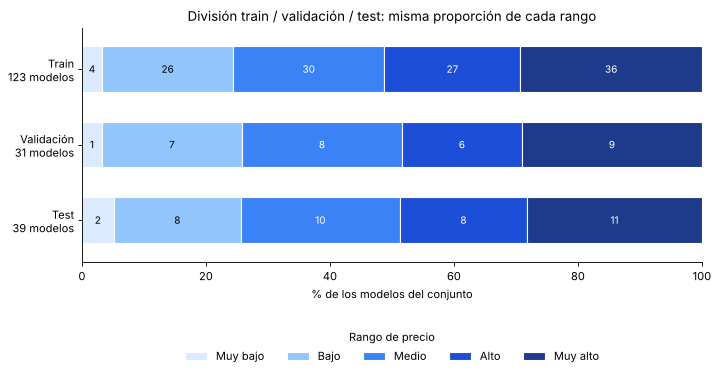

,Train,Validación,Test
Muy bajo,4,1,2
Bajo,26,7,8
Medio,30,8,10
Alto,27,6,8
Muy alto,36,9,11


In [5]:
# Gráfico: composición de cada conjunto por rango de precio (comprueba que stratify mantuvo las proporciones)
reparto = pd.DataFrame({"Train": y_tr.value_counts(), "Validación": y_val.value_counts(), "Test": y_te.value_counts()}
                       ).reindex(range(5), fill_value=0).set_axis(etiquetas)   # filas: rangos; columnas: conjuntos (n° de modelos)
pct = reparto / reparto.sum() * 100                                       # % dentro de cada conjunto (cada columna suma 100)
ax = pct.T.plot.barh(stacked=True, figsize=(10, 3.8), width=0.6, edgecolor="white",
                     color=["#dbeafe", "#93c5fd", "#3b82f6", "#1d4ed8", "#1e3a8a"])   # azul claro → oscuro = precio bajo → alto
for cont, rango, tinta in zip(ax.containers, etiquetas, ["black", "black", "white", "white", "white"]):
    ax.bar_label(cont, labels=[n if n else "" for n in reparto.loc[rango]], label_type="center", fontsize=9, color=tinta)   # n° de modelos
ax.set_yticks(range(3), [f"{s}\n{n} modelos" for s, n in reparto.sum().items()])   # nombre del conjunto + su tamaño
ax.invert_yaxis()                                                         # Train arriba
ax.set(title="División train / validación / test: misma proporción de cada rango", xlabel="% de los modelos del conjunto", xlim=(0, 100))
ax.legend(title="Rango de precio", loc="upper center", bbox_to_anchor=(0.5, -0.25), ncol=5, frameon=False)   # leyenda bajo el gráfico
ax.spines[["top", "right"]].set_visible(False)
plt.show()

reparto                                                                   # la tabla se muestra debajo del gráfico

**Interpretación.**
- Los 193 modelos quedan en **123 para entrenar, 31 para validar y 39 para test**: primero 80/20 para separar test, y luego 80/20 del resto para train y validación.

- **El `stratify` funcionó:** cada rango pesa casi lo mismo en los tres conjuntos. "Muy alto", por ejemplo, es el 29,3 %, 29,0 % y 28,2 %, y "Medio" el 24,4 %, 25,8 % y 25,6 %. Sin estratificar, por azar, algún conjunto podría quedar sin modelos "Muy bajo".

- **El límite de "Muy bajo":** con 7 modelos en total, quedan 4 para entrenar, **1 para validar y 2 para test**. La validación ajusta los hiperparámetros con un solo ejemplo de esa clase, y en test cada acierto o error mueve su recall un 50 %. Es una limitación de los datos, no del modelo.

### 2.3 Búsqueda de hiperparámetros (3 algoritmos, evaluados en validación)
Se prueban 3 algoritmos de complejidad creciente, cada uno con su grilla de hiperparámetros:
- **Regresión Logística:** modelo lineal, simple e interpretable. Necesita variables escaladas (`StandardScaler`).
- **Árbol de Decisión:** reglas del tipo "si RAM ≥ 8 GB y…", fáciles de explicar, pero tiende a sobreajustar.
- **Random Forest:** muchos árboles que votan. Suele ser más preciso y estable que un árbol solo.

Cada combinación se entrena con **train** y se evalúa con **validación**. Se elige la de mejor **F1 macro**: el promedio del F1 de los 5 rangos, que pondera igual la clase chica "Muy bajo" que la grande "Muy alto".

In [6]:
# Cada algoritmo con su grilla de hiperparámetros. Se elige la combinación con mejor F1 macro en VALIDACIÓN.
candidatos = {
    "Regresión Logística": (make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)),   # escala: la logística lo necesita
                            {"logisticregression__C": [0.01, 0.1, 1, 10, 100], "logisticregression__class_weight": [None, "balanced"]}),
    "Árbol de Decisión": (DecisionTreeClassifier(random_state=42),
                          {"max_depth": [3, 5, 7, None], "min_samples_leaf": [1, 3, 5], "class_weight": [None, "balanced"]}),
    "Random Forest": (RandomForestClassifier(random_state=42),
                      {"n_estimators": [200, 500], "max_depth": [5, 10, None], "min_samples_leaf": [1, 3], "class_weight": [None, "balanced"]}),
}   # class_weight="balanced" da más peso a los rangos con pocos celulares (ej. "Muy bajo")
res = {}
for nombre, (modelo, grilla) in candidatos.items():
    for p in ParameterGrid(grilla):                                               # prueba todas las combinaciones
        f1 = f1_score(y_val, modelo.set_params(**p).fit(X_tr, y_tr).predict(X_val), average="macro")
        if f1 > res.get(nombre, (-1,))[0]: res[nombre] = (f1, p)                   # guarda la mejor
pd.DataFrame(res, index=["F1 validación", "mejores hiperparámetros"]).T

,F1 validación,mejores hiperparámetros
Regresión Logística,0.59638,"{'logisticregression__C': 1, 'logisticregressi..."
Árbol de Decisión,0.549841,"{'class_weight': None, 'max_depth': 7, 'min_sa..."
Random Forest,0.620952,"{'class_weight': None, 'max_depth': 5, 'min_sa..."


**Interpretación.**
- **Gana Random Forest** con F1 macro de **0,62** en validación, seguido de la Regresión Logística (0,60) y el Árbol de Decisión (0,55).

- **Hiperparámetros elegidos:** 200 árboles, profundidad máxima 5 y al menos 3 modelos por hoja. Limitar la profundidad y el tamaño de las hojas evita que el modelo "memorice" los 123 celulares de entrenamiento. Dar más peso a las clases chicas (`class_weight="balanced"`) no mejoró la validación, así que quedó sin peso.

- **Cautela:** la validación tiene solo 31 modelos, con 1 solo "Muy bajo". Una diferencia de 2 a 7 puntos de F1 entre algoritmos puede ser ruido; la elección es razonable, pero no definitiva.

### 2.4 Evaluación del mejor modelo en test
El ganador se re-entrena con train + validación y se evalúa **una sola vez** con **test**, datos que no vio en ningún momento. Así la métrica estima cómo le irá con celulares nuevos, como los de la emprendedora.

Mejor modelo: Random Forest | hiperparámetros: {'class_weight': None, 'max_depth': 5, 'min_samples_leaf': 3, 'n_estimators': 200} 

              precision    recall  f1-score   support

    Muy bajo       0.00      0.00      0.00         2
        Bajo       0.56      0.62      0.59         8
       Medio       0.46      0.60      0.52        10
        Alto       0.60      0.38      0.46         8
    Muy alto       0.83      0.91      0.87        11

    accuracy                           0.62        39
   macro avg       0.49      0.50      0.49        39
weighted avg       0.59      0.62      0.59        39



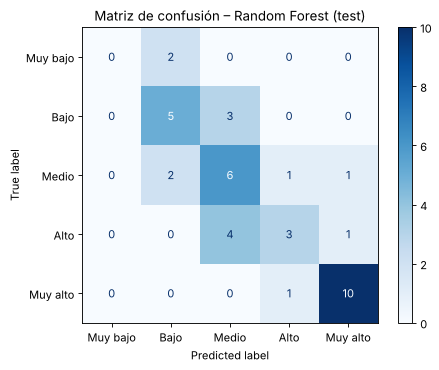

In [7]:
# El ganador se re-entrena con train + validación (80%) y se evalúa UNA vez en test.
mejor = max(res, key=lambda k: res[k][0])
modelo = candidatos[mejor][0].set_params(**res[mejor][1]).fit(X_80, y_80)
pred = modelo.predict(X_te)
print("Mejor modelo:", mejor, "| hiperparámetros:", res[mejor][1], "\n")
print(classification_report(y_te, pred, labels=range(5), target_names=etiquetas, digits=2, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_te, pred, labels=range(5), display_labels=etiquetas, cmap="Blues")
plt.title(f"Matriz de confusión – {mejor} (test)"); plt.show()

**Interpretación.**
- **En test acierta el rango exacto en 24 de 39 celulares (accuracy 0,62).** El F1 macro es 0,49 (precision 0,49 y recall 0,50).

- **Por rango:**
  - **"Muy alto"** es el mejor (F1 0,87): reconoce 10 de 11.
  - **"Bajo"** (0,59) y **"Medio"** (0,52) quedan en un nivel intermedio.
  - **"Alto"** es el más difícil entre las clases grandes (recall 0,38): 4 de sus 8 celulares se confunden con "Medio", porque ambos rangos comparten la configuración típica de 8 GB de RAM y 256 GB.
  - **"Muy bajo"** queda en 0: sus 2 celulares (Tecno Spark Go 3 a \$89.990 y Bmobile Dots Ultra a \$99.990) se clasifican como "Bajo".

- **"Muy bajo" no se puede distinguir por características:** esos dos equipos están a menos de \$10 mil del corte de \$100 mil y traen lo mismo que los "Bajo" (4 GB de RAM). Esa clase arrastra el F1 macro: sin ella, el F1 promedio de los otros 4 rangos es 0,61.

- **Los errores caen casi siempre en el rango vecino:** 14 de los 15 errores son a un rango de distancia, así que el **97 % de los celulares** de test queda en su rango o en el adyacente. El único salto mayor es el TCL 60 NxtPaper Ultra: trae 512 GB y 12 GB a \$299.990 y el modelo lo ubica en "Muy alto". Es una "ganga" que ningún modelo basado solo en características puede anticipar.

### 2.5 Variables más influyentes
**Importancia por permutación:** se desordena una variable a la vez en test y se mide cuánto cae el F1. Si al desordenarla el modelo empeora mucho, esa variable era importante. Sirve para cualquier algoritmo, y se repite 30 veces para que el resultado no dependa del azar.

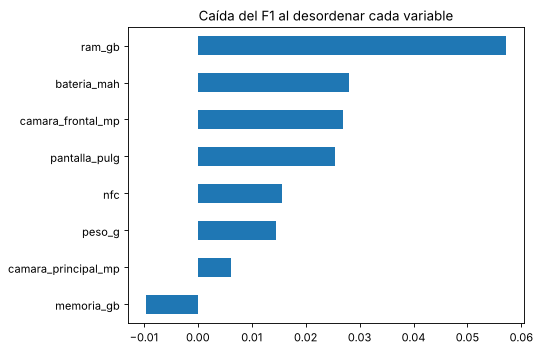

In [8]:
# Importancia por permutación: cuánto cae el F1 si "desordenamos" una variable (sirve para cualquier modelo)
imp = permutation_importance(modelo, X_te, y_te, scoring="f1_macro", n_repeats=30, random_state=42)
pd.Series(imp.importances_mean, X_cols).sort_values().plot.barh(title="Caída del F1 al desordenar cada variable")
plt.show()

**Interpretación.**
- **La RAM es, por lejos, la variable más influyente:** al desordenarla, el F1 cae 0,057, el doble que cualquier otra. Coincide con la pregunta a, donde la RAM separa las gamas y Samsung cobra justamente por ella.

- **Un segundo grupo tiene efectos menores y parecidos:** batería (0,028), cámara frontal (0,027) y pantalla (0,025), y luego NFC (0,016) y peso (0,014). La cámara principal casi no aporta (0,006).

- **La memoria sale levemente negativa (−0,010).** No significa que no importe: se superpone con la RAM (equipos con más RAM traen más memoria), así que al desordenarla el modelo sigue informándose por la RAM. En la correlación de la pregunta a destacaba por los iPhone de 1 TB, que aquí son pocos entre 193 modelos.

- **Cautela:** la variación entre las 30 repeticiones es amplia (desviación de 0,02 a 0,07), mayor que la mayoría de los efectos. Solo el liderazgo de la RAM es robusto; el orden del resto puede cambiar con otra muestra.

### 2.6 Conclusión del Objetivo 2
- **Mejor modelo: Random Forest** (F1 macro de 0,62 en validación). En test acierta el rango exacto en el **62 %** de los celulares, y en el **97 %** se equivoca a lo más por un rango.

- **Para la emprendedora:** sirve como **estimador de rango**. Con las características de un equipo nuevo, lo ubica en su rango de precio o en el vecino. Las palancas que más mueven el rango son la RAM y, en menor medida, la batería, la pantalla y la cámara frontal.

- **Limitaciones:**
  1. **"Muy bajo" no es predecible** con estos datos: son solo 7 modelos, y el corte de \$100 mil separa equipos con características casi iguales.
  2. **Muestras pequeñas** (193 modelos; 39 en test): las métricas pueden variar varios puntos con otra división. Como referencia, el árbol de decisión obtuvo un F1 de 0,55 en test, más que el Random Forest (0,49). Ese dato no se usa para elegir, porque sería mirar el test, pero confirma que con tan pocos datos la diferencia entre algoritmos está dentro del ruido.
  3. **Variables no incluidas:** el procesador y la tasa de refresco, que distinguen gamas, y la marca, que se excluye a propósito porque los equipos de la emprendedora no tienen historia de marca.
  4. **Variantes de 1 TB:** por la regla de la primera variante, 6 iPhone entran con su versión más cara.

- **Próximos pasos:** agregar el procesador (ya está en `data_raw.csv`) y usar validación cruzada para elegir el modelo con menos ruido que una sola división.